# Hydrograph statistical companion
Separate investigation; frozen model unchanged. Read DESIGN.md for the durable research contract and RESULTS.md for interpretation. All inference is exploratory; no causal effects or significance tests.


In [2]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
while not (ROOT/'RAPID').exists():
    if ROOT == ROOT.parent: raise RuntimeError('Run inside repository')
    ROOT=ROOT.parent
OUT=ROOT/'RAPID/outputs/hydrograph_statistical_companion_20261019'
scores=pd.read_csv(OUT/'scores.csv')
display(scores.query("target=='centroid' and training_scenario=='all' and evaluation=='all'"))


,model,training_scenario,evaluation,target,n,networks,r2,mae_minutes,relative_error_pct
0,frozen_forest,all,all,centroid,2170,15,0.614531,2.822441,63.737195
8,mixed,all,all,centroid,2170,15,0.070013,6.580054,224.694825
22,wls,all,all,centroid,2170,15,0.257091,5.008957,144.485710


## Associations and uncertainty
Pointwise whole-network bootstrap intervals, 2,000 draws, only 15 observed networks. Marginal IQR contrasts can have poor joint support under collinearity.


,model,term,coefficient_minutes,pointwise_low,pointwise_high,bootstrap_successes,bootstrap_same_sign,lono_min,lono_max,lono_same_sign,q25,q75,iqr_effect_minutes,iqr_low,iqr_high,reference_delta_transformed,reference_effect_minutes,reference_low,reference_high
0,mixed,log1p__B_ratio_route_length_mean,109.067702,-35.828409,260.412456,2000,0.9115,27.814324,167.032122,1.000000,0.660853,0.692983,3.504423,-1.151192,8.367237,0.287682,31.376822,-10.307191,74.915995
1,mixed,domain_size,-0.059514,-0.817695,-0.017917,2000,0.9990,-0.145147,-0.049631,1.000000,2.409789,13.535153,-0.662114,-9.097153,-0.199336,1.000000,-0.059514,-0.817695,-0.017917
2,mixed,log1p__B_ratio_route_length_sd,4.247233,1.709703,9.314222,2000,1.0000,3.012118,5.225158,1.000000,0.000000,0.696635,2.958770,1.191039,6.488611,0.287682,1.221853,0.491851,2.679535
3,mixed,log1p__B_ratio_width_mean,-93.245110,-168.349079,-46.526974,2000,1.0000,-102.270888,-61.250227,1.000000,0.711424,1.100085,-36.240745,-65.430734,-18.083224,0.287682,-26.824947,-48.431012,-13.384976
4,mixed,log1p__B_ratio_width_cv,-18.033363,-30.148537,-11.418064,2000,1.0000,-19.297354,-13.724358,1.000000,0.000000,0.695048,-12.534045,-20.954667,-7.936097,0.287682,-5.187875,-8.673194,-3.284772
5,mixed,log1p__B_ratio_route_entropy,-36.503064,-77.365801,-3.923426,2000,0.9870,-40.975504,-19.028988,1.000000,0.000000,0.676402,-24.690761,-52.330415,-2.653815,0.287682,-10.501277,-22.256754,-1.128699
6,mixed,B_parent_dominance_mean,15.414525,1.067773,36.068813,2000,0.9845,11.389791,24.093570,1.000000,0.654629,0.744898,1.391455,0.096387,3.255899,0.100000,1.541452,0.106777,3.606881
7,wls,log1p__B_ratio_route_length_mean,8.243130,-75.033064,124.661940,2000,0.5975,-26.955962,24.555653,0.800000,0.660853,0.692983,0.264858,-2.410866,4.005477,0.287682,2.371401,-21.585667,35.863005
8,wls,domain_size,-0.030311,-0.870834,-0.008966,2000,0.9985,-0.052496,-0.025769,1.000000,2.409789,13.535153,-0.337219,-9.688351,-0.099755,1.000000,-0.030311,-0.870834,-0.008966
9,wls,log1p__B_ratio_route_length_sd,0.124178,-2.330493,3.934131,2000,0.5905,-0.352490,2.356743,0.533333,0.000000,0.696635,0.086507,-1.623503,2.740652,0.287682,0.035724,-0.670441,1.131779


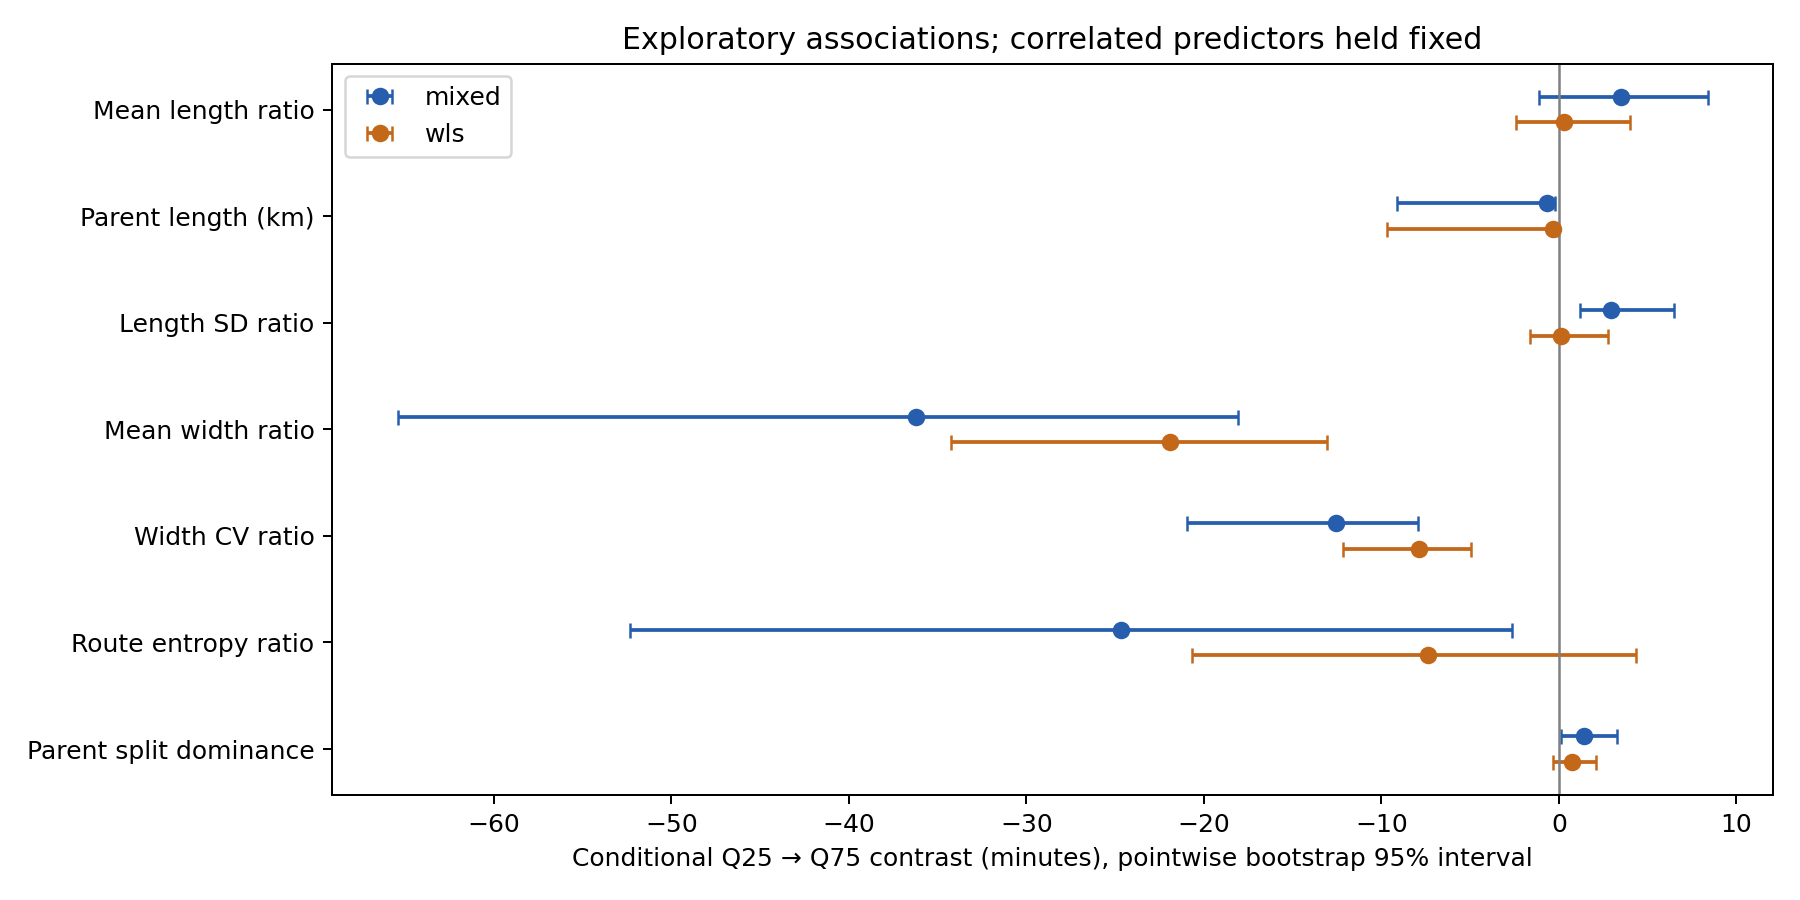

In [4]:
display(pd.read_csv(OUT/'effects_uncertainty.csv'))
display(Image(filename=str(OUT/'effect_contrasts.png')))


## Dependence and collinearity
Response parents are shared within networks; geometric parent signatures recur across edits.


In [6]:
display(pd.read_csv(OUT/'dependence_audit.csv',dtype={'example':str}))
display(pd.read_csv(OUT/'collinearity.csv'))


,example,n,response_parent,parent_signatures,overlap_groups,repeated_parent_rows
0,02,35,S000_base,6,6,34
1,03,40,S000_base,15,15,32
2,05,51,S000_base,34,34,25
3,13,66,S000_base,30,30,46
4,15,262,S000_base,11,11,258
5,21,30,S000_base,19,19,16
6,22,408,S000_base,14,14,401
7,37,395,S000_base,3,3,394
8,41,181,S000_base,37,37,162
9,45,93,S000_base,34,34,78


,view,feature,vif,condition_number
0,pooled,log1p__B_ratio_route_length_mean,2.749051,8.602771
1,pooled,domain_size,1.353744,8.602771
2,pooled,log1p__B_ratio_route_length_sd,3.150811,8.602771
3,pooled,log1p__B_ratio_width_mean,7.802202,8.602771
4,pooled,log1p__B_ratio_width_cv,6.947951,8.602771
5,pooled,log1p__B_ratio_route_entropy,12.285511,8.602771
6,pooled,B_parent_dominance_mean,1.110388,8.602771
7,within_network,log1p__B_ratio_route_length_mean,2.325218,7.478128
8,within_network,domain_size,1.068320,7.478128
9,within_network,log1p__B_ratio_route_length_sd,2.775215,7.478128


## Exclusions versus refits
training_scenario=all retains original training. Other scenarios remove observations before every fit. Forest rows are evaluation-only rescoring.


In [8]:
display(scores.query("target=='centroid'"))
display(pd.read_csv(OUT/'refit_coefficient_sensitivity.csv'))


,model,training_scenario,evaluation,target,n,networks,r2,mae_minutes,relative_error_pct
0,frozen_forest,all,all,centroid,2170,15,0.614531,2.822441,63.737195
2,frozen_forest,all,without54,centroid,2089,14,0.622110,2.840336,60.043284
4,frozen_forest,all,without_extreme,centroid,2169,15,0.713366,2.761200,63.732924
6,frozen_forest,all,without_both,centroid,2088,14,0.725224,2.774721,60.038708
8,mixed,all,all,centroid,2170,15,0.070013,6.580054,224.694825
10,mixed,all,without54,centroid,2089,14,0.135636,6.504747,213.595472
12,mixed,all,without_extreme,centroid,2169,15,-0.008960,6.518452,224.711481
14,mixed,all,without_both,centroid,2088,14,0.078002,6.438745,213.613317
16,mixed,without54,without54,centroid,2089,14,0.088370,6.743569,225.808441
18,mixed,without_both,without_both,centroid,2088,14,0.175069,5.864234,195.747017


,model,term,all,without54,without_both,without_extreme
0,mixed,B_parent_dominance_mean,15.414525,16.235853,12.575389,11.678895
1,mixed,domain_size,-0.059514,-0.060964,-0.047927,-0.046206
2,mixed,intercept,16.275282,-19.840697,-39.777642,-14.432036
3,mixed,log1p__B_ratio_route_entropy,-36.503064,-40.826420,-23.485442,-20.618755
4,mixed,log1p__B_ratio_route_length_mean,109.067702,167.032122,144.100380,103.916303
5,mixed,log1p__B_ratio_route_length_sd,4.247233,4.052037,4.510888,4.591211
6,mixed,log1p__B_ratio_width_cv,-18.033363,-17.849214,-14.333677,-14.465671
7,mixed,log1p__B_ratio_width_mean,-93.245110,-95.690793,-63.549605,-61.736100
8,wls,B_parent_dominance_mean,8.404758,11.052745,9.882687,7.101121
9,wls,domain_size,-0.030311,-0.030247,-0.018565,-0.018980


## Linear adequacy
Descriptive held-network binned residuals; no smooth model fitted. Patterns are not proof of a particular nonlinear or physical mechanism.


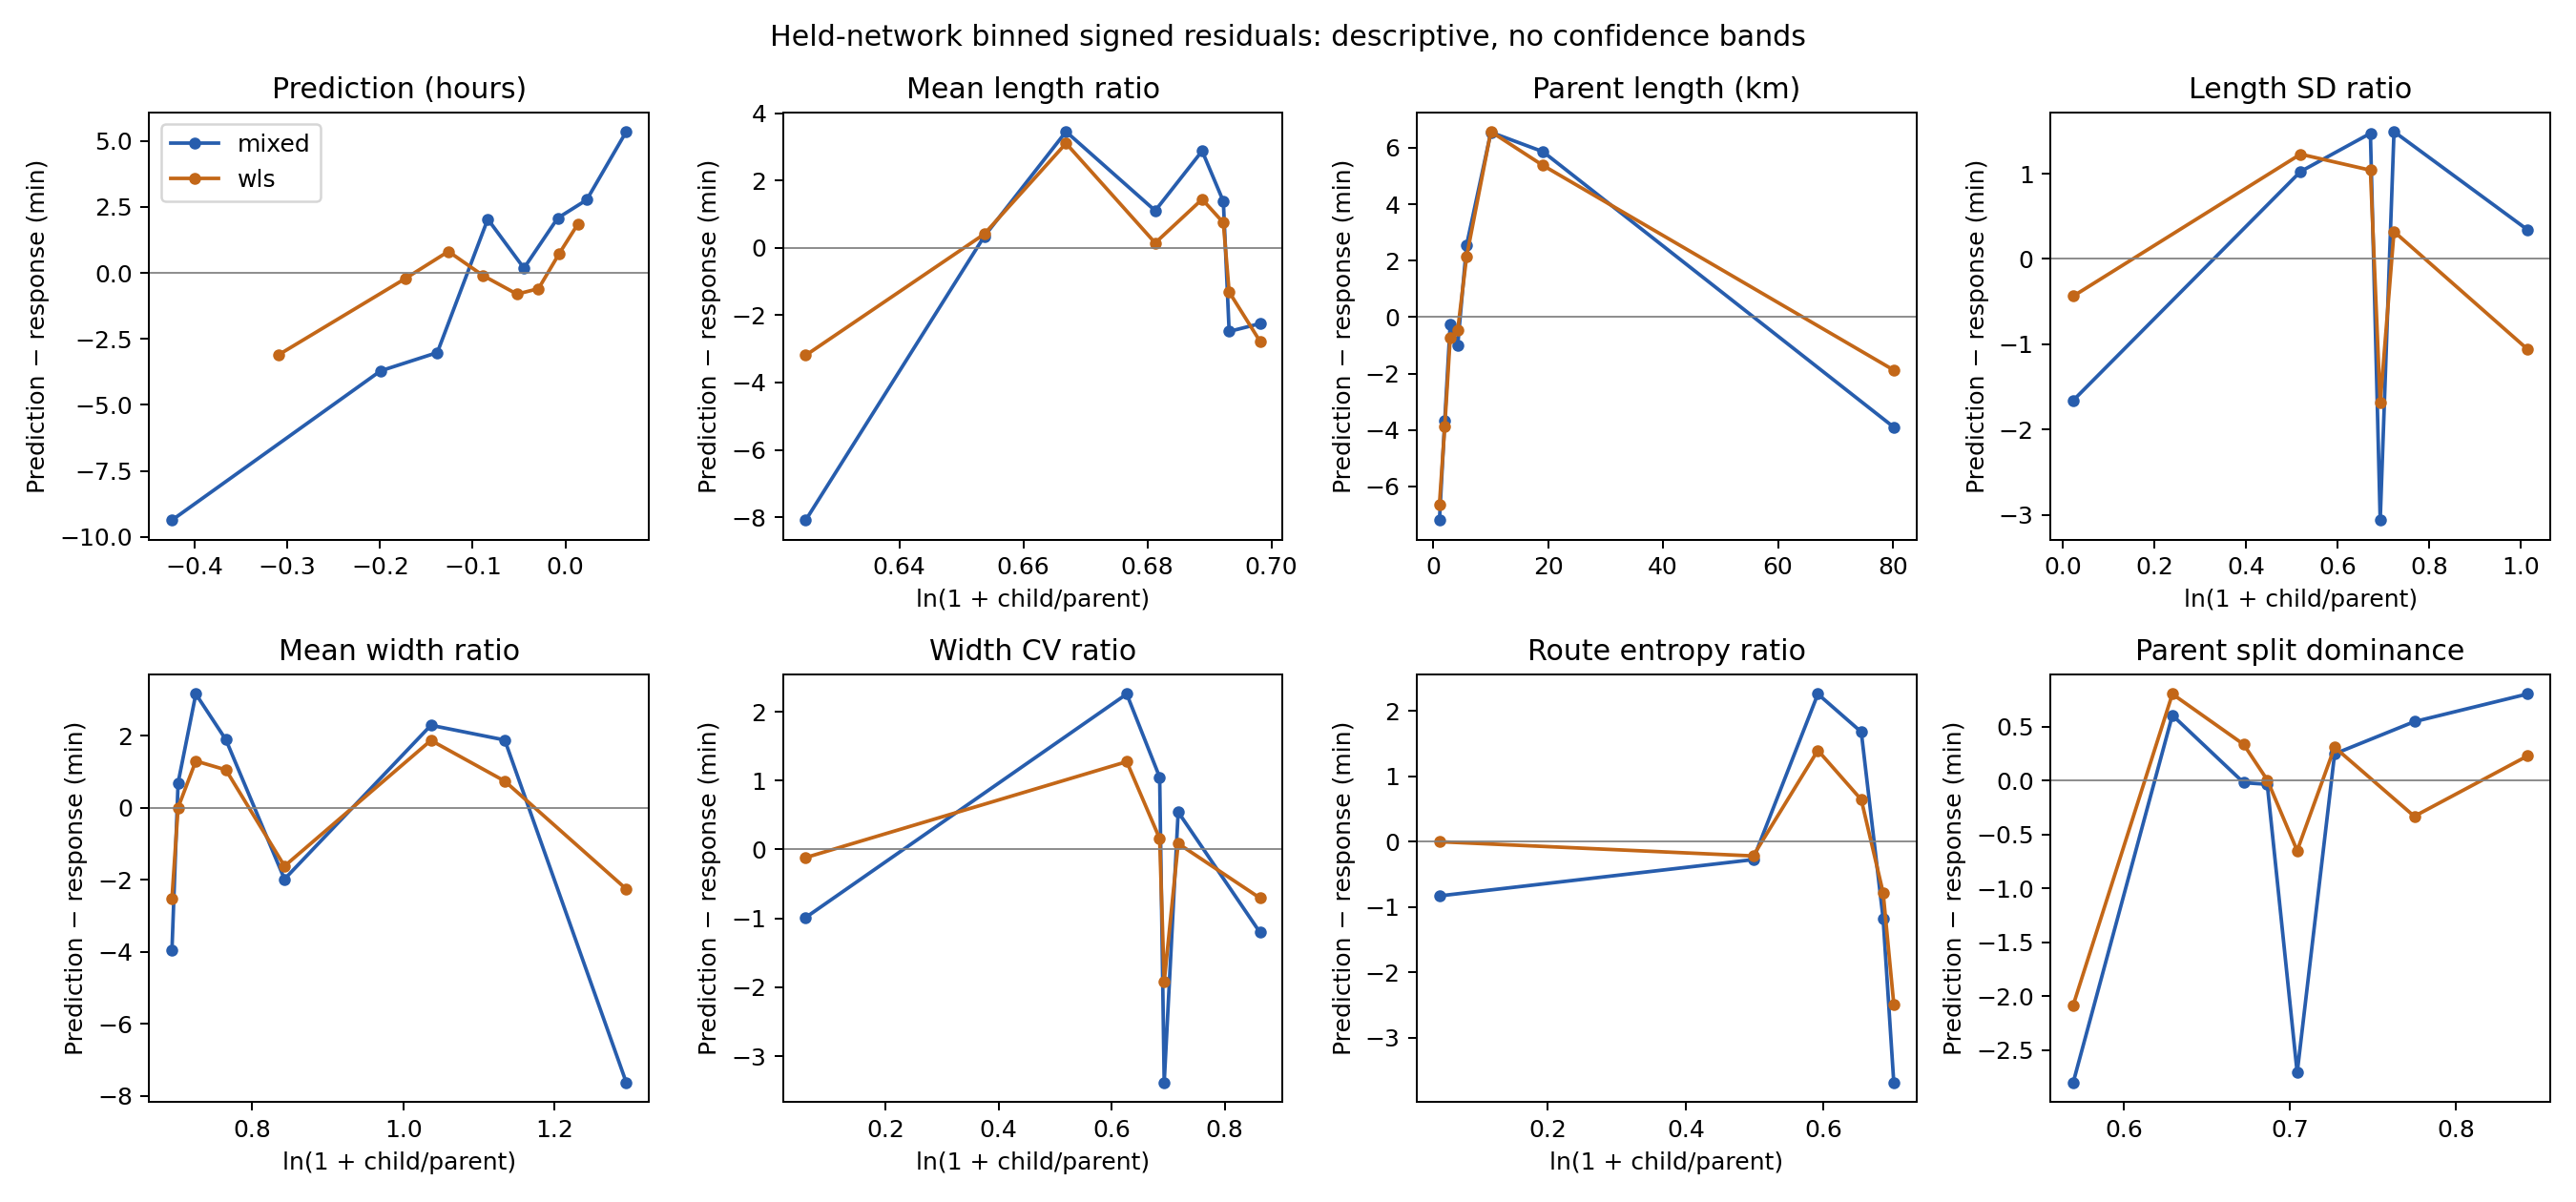

,term,quantile,endpoint,median_nearest_distance,p90_nearest_distance,note
0,log1p__B_ratio_route_length_mean,0.25,0.660853,0.507078,1.157970,Standardized Euclidean distance to any observe...
1,log1p__B_ratio_route_length_mean,0.75,0.692983,0.252252,0.782578,Standardized Euclidean distance to any observe...
2,domain_size,0.25,2.409789,0.086328,0.266838,Standardized Euclidean distance to any observe...
3,domain_size,0.75,13.535153,0.269369,0.407007,Standardized Euclidean distance to any observe...
4,log1p__B_ratio_route_length_sd,0.25,0.000000,0.672043,1.469739,Standardized Euclidean distance to any observe...
5,log1p__B_ratio_route_length_sd,0.75,0.696635,0.282994,1.787475,Standardized Euclidean distance to any observe...
6,log1p__B_ratio_width_mean,0.25,0.711424,0.342537,1.623143,Standardized Euclidean distance to any observe...
7,log1p__B_ratio_width_mean,0.75,1.100085,0.917903,1.293088,Standardized Euclidean distance to any observe...
8,log1p__B_ratio_width_cv,0.25,0.000000,1.325587,1.990780,Standardized Euclidean distance to any observe...
9,log1p__B_ratio_width_cv,0.75,0.695048,0.235817,1.916161,Standardized Euclidean distance to any observe...


In [10]:
display(Image(filename=str(OUT/'residual_patterns.png')))
display(pd.read_csv(OUT/'contrast_support.csv'))


## Peak transfer
These are centroid predictions evaluated against peak shifts, not a separately fitted peak model. Whole-network states remain outside this cohort.


In [12]:
display(scores.query("target=='peak_transfer' and training_scenario=='all' and evaluation=='all'"))


,model,training_scenario,evaluation,target,n,networks,r2,mae_minutes,relative_error_pct
1,frozen_forest,all,all,peak_transfer,2170,15,0.490950,4.544079,74.218503
9,mixed,all,all,peak_transfer,2170,15,0.173593,7.892237,217.452067
23,wls,all,all,peak_transfer,2170,15,0.225358,6.548267,149.949996
